In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## **Veri Hazırlama Aşaması**

In [ ]:
import os
import shutil
import random
from sklearn.model_selection import train_test_split
from glob import glob

dataset_path = "/content/drive/MyDrive/dernet4"

output_dir = "/content/dermnet_split"

train_ratio = 0.70
test_ratio = 0.30

RANDOM_STATE = 42

random.seed(RANDOM_STATE)

for subset in ["train", "test"]:
    os.makedirs(os.path.join(output_dir, subset), exist_ok=True)

classes = [d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))]
classes.sort()
print("Found classes:", classes)

summary = {}

for cls in classes:
    class_src = os.path.join(dataset_path, cls)

    files = []
    for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.tif", "*.tiff"):
        files.extend(glob(os.path.join(class_src, ext)))
    files = sorted(files)
    n = len(files)
    if n == 0:
        print(f"{cls} klasöründe hiç görüntü yok: {class_src}")
        continue

    random.shuffle(files)

    train_count = int(n * train_ratio)
    test_count = n - train_count

    train_files = files[:train_count]
    test_files  = files[train_count:]

    for subset, flist in [("train", train_files), ("test", test_files)]:
        dest_folder = os.path.join(output_dir, subset, cls)
        os.makedirs(dest_folder, exist_ok=True)
        for fp in flist:
            shutil.copy2(fp, dest_folder)

    summary[cls] = {"total": n, "train": len(train_files), "test": len(test_files)}
    print(f"{cls}: total={n}, train={len(train_files)}, test={len(test_files)}")

Found classes: ['Eczema Photos', 'Lichen Planus', 'gül_hast', 'mantar', 'sedef']
Eczema Photos: total=600, train=420, test=180
Lichen Planus: total=600, train=420, test=180
gül_hast: total=600, train=420, test=180
mantar: total=600, train=420, test=180
sedef: total=600, train=420, test=180


## **Veri Dönüşümü**

In [ ]:
import torch
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
INPUT_SIZE = 224
CROP_SIZE = 224

train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(CROP_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

val_test_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(CROP_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

## **Veri Yükleme**

In [ ]:
DATA_ROOT = '/content/dermnet_split'
BATCH_SIZE = 32
NUM_WORKERS = 2

print("Veri Setleri Yükleniyor...")

train_dataset = ImageFolder(
    root=f'{DATA_ROOT}/train',
    transform=train_transforms
)

test_dataset = ImageFolder(
    root=f'{DATA_ROOT}/test',
    transform=val_test_transforms
)

class_names = train_dataset.classes
num_classes = len(class_names)
print(f"Sınıf İsimleri (Toplam {num_classes} Sınıf): {class_names}")

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

print("\n--- Veri Yükleyici Özeti ---")
print(f"Toplam Eğitim Örneği: {len(train_dataset)}")
print(f"Toplam Test Örneği: {len(test_dataset)}")
print(f"Eğitim Batch Sayısı: {len(train_loader)}")
print(f"Batch Büyüklüğü: {BATCH_SIZE}")

Veri Setleri Yükleniyor...
Sınıf İsimleri (Toplam 5 Sınıf): ['Eczema Photos', 'Lichen Planus', 'gül_hast', 'mantar', 'sedef']

--- Veri Yükleyici Özeti ---
Toplam Eğitim Örneği: 2100
Toplam Test Örneği: 900
Eğitim Batch Sayısı: 66
Batch Büyüklüğü: 32


## *Model Yükleme ve Transfer Learning (Feature Extractor Hazırlama)*

In [ ]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

model_ft = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

for param in model_ft.parameters():
    param.requires_grad = False

in_features = model_ft.classifier[1].in_features

model_ft.classifier[1] = nn.Linear(in_features, num_classes)

model_ft = model_ft.to(device)

print("EfficientNetB0 modeli hazır.")
print(model_ft)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 138MB/s]


EfficientNetB0 modeli hazır.
EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
   

*Modelin Son Katmanını Yeniden Yazma (Classifier Fine-Tuning)*

In [ ]:
NUM_CLASSES = num_classes

num_ftrs = model_ft.classifier[1].in_features

model_ft.classifier = nn.Sequential(
    nn.Dropout(p=0.2, inplace=True),
    nn.Linear(num_ftrs, NUM_CLASSES)
)

model_ft = model_ft.to(device)

print(f"EfficientNetB0 modeli {device} cihazına yüklendi ve son katman {NUM_CLASSES} sınıfa göre ayarlandı.")

EfficientNetB0 modeli cpu cihazına yüklendi ve son katman 5 sınıfa göre ayarlandı.


## *Eğitim Ayarları (Training Setup: Optimizer + Loss Function)*

In [ ]:
import torch.optim as optim

params_to_update = [param for param in model_ft.parameters() if param.requires_grad]

optimizer_ft = optim.Adam(params_to_update, lr=0.001)

criterion = nn.CrossEntropyLoss()

print("Optimizasyon algoritması (Adam) ve Kayıp Fonksiyonu (CrossEntropyLoss) tanımlandı.")

Optimizasyon algoritması (Adam) ve Kayıp Fonksiyonu (CrossEntropyLoss) tanımlandı.


## *Model Eğitimi (Training Loop / Fine-Tuning)*

In [ ]:
import time
import copy
import torch
from tqdm import tqdm

num_epochs = 25

best_model_wts = copy.deepcopy(model_ft.state_dict())
best_acc = 0.0

def train_model(model, dataloaders, criterion, optimizer, num_epochs=25, device=device):
    global best_acc
    global best_model_wts

    since = time.time()

    for epoch in range(num_epochs):
        print(f'Epoch {epoch}/{num_epochs - 1}')
        print('-' * 10)

        phase = 'train'
        model.train()
        dataloader = dataloaders['train']

        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in tqdm(dataloader, desc='Training'):
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            with torch.set_grad_enabled(True):
                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                loss = criterion(outputs, labels)

                loss.backward()
                optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        epoch_loss = running_loss / len(dataloader.dataset)
        epoch_acc = running_corrects.double() / len(dataloader.dataset)

        print(f'Train Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

        if epoch_acc > best_acc:
            best_acc = epoch_acc
            best_model_wts = copy.deepcopy(model.state_dict())

        print()

    time_elapsed = time.time() - since
    print(f'Eğitim Tamamlandı: {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'En İyi Train Acc: {best_acc:.4f}')

    model.load_state_dict(best_model_wts)
    return model

dataloaders = {
    'train': train_loader
}

model_ft = train_model(
    model_ft,
    dataloaders,
    criterion,
    optimizer_ft,
    num_epochs=num_epochs,
    device=device
)

Epoch 0/24
----------


Training: 100%|██████████| 66/66 [04:01<00:00,  3.66s/it]


Train Loss: 1.2992 Acc: 0.5038

Epoch 1/24
----------


Training: 100%|██████████| 66/66 [03:48<00:00,  3.46s/it]


Train Loss: 1.0109 Acc: 0.6233

Epoch 2/24
----------


Training: 100%|██████████| 66/66 [03:47<00:00,  3.44s/it]


... (41 outputs left out)

Training: 100%|██████████| 66/66 [03:51<00:00,  3.51s/it]


Train Loss: 0.6448 Acc: 0.7557

Epoch 24/24
----------


Training: 100%|██████████| 66/66 [03:50<00:00,  3.49s/it]

Train Loss: 0.6422 Acc: 0.7510

Eğitim Tamamlandı: 96m 43s
En İyi Train Acc: 0.7595


## *Model Değerlendirme (Evaluation / Testing)*

In [ ]:
import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from tqdm import tqdm

def evaluate_model(model, test_loader, device, class_names):

    model.eval()
    all_preds = []
    all_labels = []

    print("\n--- Test Aşamasında ---")

    with torch.no_grad():
        for inputs, labels in tqdm(test_loader, desc='Testing'):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1);

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)

    test_accuracy = np.mean(all_preds == all_labels)
    print(f"\nTest Veri Seti Doğruluğu: {test_accuracy:.4f}")

    print("\n--- Sınıflandırma Raporu (Precision, Recall, F1-Score) ---")
    print(classification_report(all_labels, all_preds, target_names=class_names, zero_division=0))

    print("\n--- Karmaşıklık Matrisi (Confusion Matrix) ---")
    cm = confusion_matrix(all_labels, all_preds)

    try:
        import pandas as pd
        cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
        print(cm_df)
    except ImportError:
        print(cm)

    return test_accuracy, cm, all_labels, all_preds

global_test_accuracy, global_confusion_matrix_result, global_all_labels, global_all_preds = evaluate_model(
    model_ft,
    test_loader,
    device,
    class_names
)


--- Test Aşamasında ---


Testing: 100%|██████████| 29/29 [01:24<00:00,  2.91s/it]


Test Veri Seti Doğruluğu: 0.7322

--- Sınıflandırma Raporu (Precision, Recall, F1-Score) ---
               precision    recall  f1-score   support

Eczema Photos       0.68      0.56      0.61       180
Lichen Planus       0.76      0.86      0.80       180
    gül_hast       0.91      0.98      0.94       180
       mantar       0.59      0.71      0.64       180
        sedef       0.72      0.57      0.63       180

     accuracy                           0.73       900
    macro avg       0.73      0.73      0.73       900
 weighted avg       0.73      0.73      0.73       900


--- Karmaşıklık Matrisi (Confusion Matrix) ---
               Eczema Photos  Lichen Planus  gül_hast  mantar  sedef
Eczema Photos            100             13          9      35     23
Lichen Planus              5            154          5      11      5
gül_hast                  0              1        176       2      1
mantar                    22             17          3     127     11
sedef     

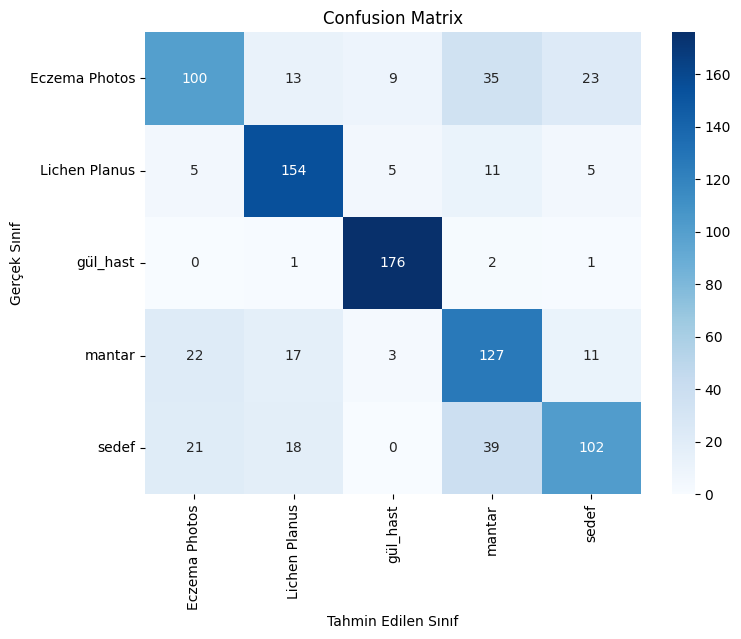

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(global_all_labels, global_all_preds)
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)

plt.figure(figsize=(8,6))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.ylabel("Gerçek Sınıf")
plt.xlabel("Tahmin Edilen Sınıf")
plt.show()

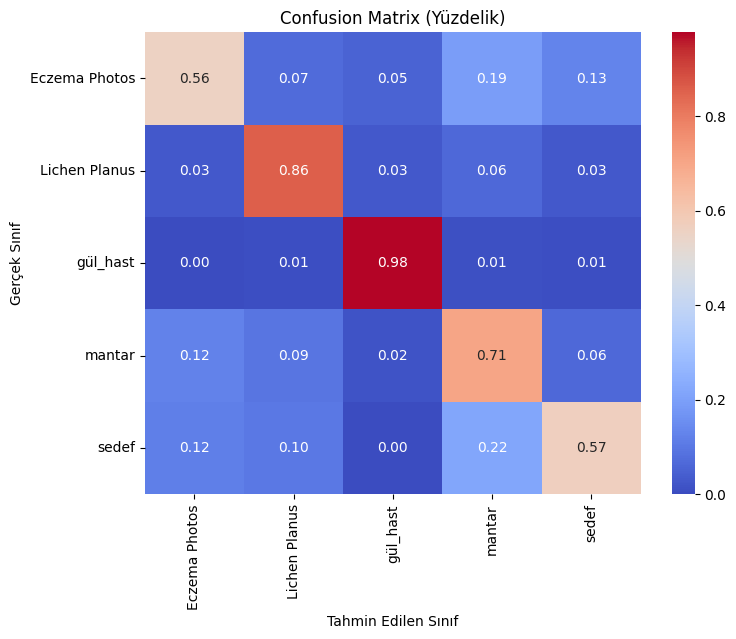

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(global_all_labels, global_all_preds)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]  # satır bazında yüzdelik

cm_df = pd.DataFrame(cm_percent, index=class_names, columns=class_names)

plt.figure(figsize=(8,6))
sns.heatmap(cm_df, annot=True, fmt='.2f', cmap='coolwarm', cbar=True)
plt.title("Confusion Matrix (Yüzdelik)")
plt.ylabel("Gerçek Sınıf")
plt.xlabel("Tahmin Edilen Sınıf")
plt.show()

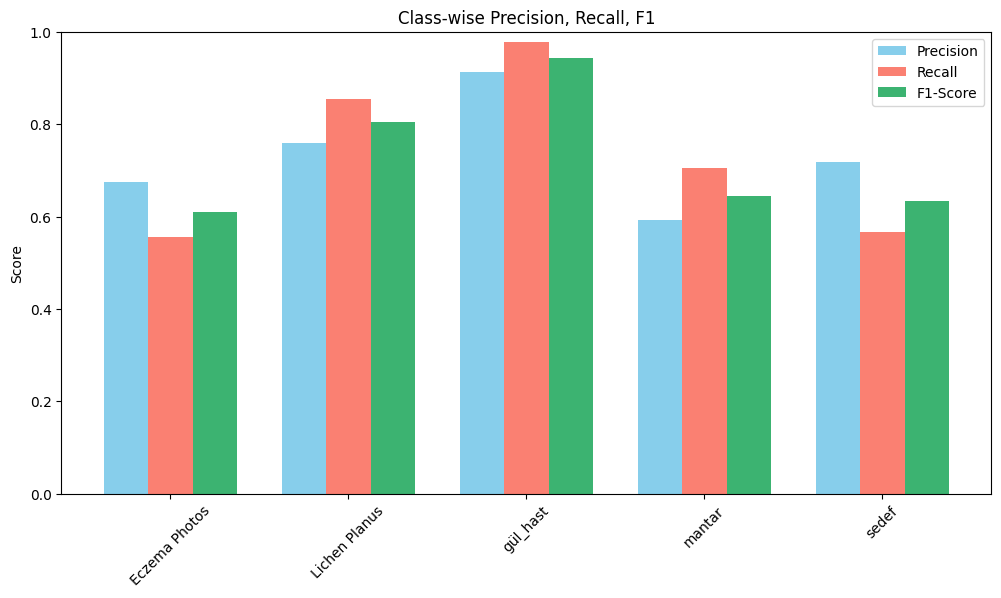

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import matplotlib.pyplot as plt

precisions = precision_score(global_all_labels, global_all_preds, average=None, zero_division=0)
recalls = recall_score(global_all_labels, global_all_preds, average=None, zero_division=0)
f1_scores = f1_score(global_all_labels, global_all_preds, average=None, zero_division=0)

x = np.arange(len(class_names))
width = 0.25

plt.figure(figsize=(12,6))
plt.bar(x - width, precisions, width, label='Precision', color='skyblue')
plt.bar(x, recalls, width, label='Recall', color='salmon')
plt.bar(x + width, f1_scores, width, label='F1-Score', color='mediumseagreen')
plt.xticks(x, class_names, rotation=45)
plt.ylim(0,1)
plt.ylabel("Score")
plt.title("Class-wise Precision, Recall, F1")
plt.legend()
plt.show()

/tmp/ipython-input-1832615532.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_names, y=class_acc, palette="viridis")


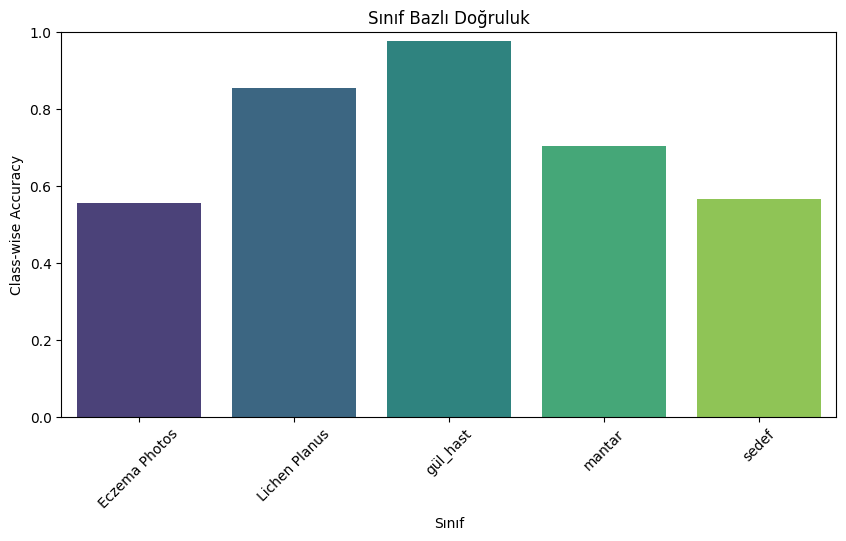

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

class_acc = cm.diagonal() / cm.sum(axis=1)

plt.figure(figsize=(10,5))
sns.barplot(x=class_names, y=class_acc, palette="viridis")
plt.ylim(0,1)
plt.ylabel("Class-wise Accuracy")
plt.xlabel("Sınıf")
plt.title("Sınıf Bazlı Doğruluk")
plt.xticks(rotation=45)
plt.show()


--- Collecting Probabilities for ROC Curve ---


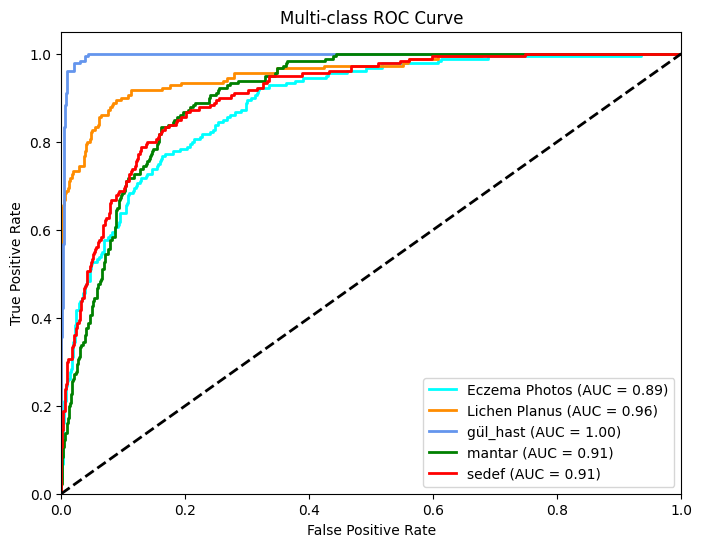

In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from itertools import cycle
import torch
import numpy as np
from tqdm import tqdm

model_ft.eval()

all_labels = []
all_probs = []

print("\n--- Collecting Probabilities for ROC Curve ---")
with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc='Collecting Probabilities'):
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model_ft(inputs)
        probabilities = torch.softmax(outputs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probabilities.cpu().numpy())

all_labels = np.array(all_labels)
all_probs = np.array(all_probs)

all_labels_bin = label_binarize(all_labels, classes=range(len(class_names)))
n_classes = len(class_names)

plt.figure(figsize=(8,6))
colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green', 'red'])
for i, color in zip(range(n_classes), colors):
    if np.sum(all_labels_bin[:, i]) == 0 or np.sum(all_probs[:, i]) == 0:
        print(f"Warning: Skipping ROC for class {class_names[i]} due to no samples or predictions.")
        continue

    fpr, tpr, _ = roc_curve(all_labels_bin[:, i], all_probs[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2, label=f'{class_names[i]} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multi-class ROC Curve")
plt.legend(loc="lower right")
plt.show()

## *Full Fine-Tuning (Unfreeze All Layers)*

In [ ]:
import torch.optim as optim
import time
import copy
from tqdm import tqdm

model_ft = model_ft.to(device)

for param in model_ft.parameters():
    param.requires_grad = True

print("EfficientNetB0 içindeki tüm katmanlar eğitime açıldı (unfrozen).")

FULL_FT_LEARNING_RATE = 1e-5

optimizer_full_ft = optim.Adam(model_ft.parameters(), lr=FULL_FT_LEARNING_RATE)

criterion = nn.CrossEntropyLoss()

FULL_FT_NUM_EPOCHS = 10

print(f"\n--- Fine-Tuning Başlıyor (LR: {FULL_FT_LEARNING_RATE}) ---")
print(f"Toplam Epoch: {FULL_FT_NUM_EPOCHS}")

model_ft_tuned = train_model(
    model_ft,
    dataloaders,
    criterion,
    optimizer_full_ft,
    num_epochs=FULL_FT_NUM_EPOCHS,
    device=device
)

EfficientNetB0 içindeki tüm katmanlar eğitime açıldı (unfrozen).

--- Fine-Tuning Başlıyor (LR: 1e-05) ---
Toplam Epoch: 10
Epoch 0/9
----------


Training: 100%|██████████| 66/66 [09:17<00:00,  8.45s/it]


Train Loss: 0.6046 Acc: 0.7733

Epoch 1/9
----------


Training: 100%|██████████| 66/66 [09:12<00:00,  8.38s/it]


Train Loss: 0.6092 Acc: 0.7667

Epoch 2/9
----------


Training: 100%|██████████| 66/66 [09:09<00:00,  8.33s/it]


... (11 outputs left out)

Training: 100%|██████████| 66/66 [09:14<00:00,  8.41s/it]


Train Loss: 0.4633 Acc: 0.8348

Epoch 9/9
----------


Training: 100%|██████████| 66/66 [09:05<00:00,  8.26s/it]

Train Loss: 0.4731 Acc: 0.8276

Eğitim Tamamlandı: 91m 23s
En İyi Train Acc: 0.8348


## *Test Set Üzerinde Gelişmiş Değerlendirme:*

In [ ]:
import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from tqdm import tqdm

def evaluate_model(model, test_loader, device, class_names):

    model.eval()
    all_preds = []
    all_labels = []

    print("\n--- Test Aşaması Başladı ---")

    with torch.no_grad():
        for inputs, labels in tqdm(test_loader, desc='Testing'):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)

    test_accuracy = np.mean(all_preds == all_labels)
    print(f"\nTest Accuracy: {test_accuracy:.4f}")

    print("\n--- Classification Report ---")
    print(classification_report(all_labels, all_preds, target_names=class_names, zero_division=0))

    print("\n--- Confusion Matrix ---")
    cm = confusion_matrix(all_labels, all_preds)

    return test_accuracy, cm, all_labels, all_preds
test_accuracy, confusion_matrix_result, all_labels, all_preds = evaluate_model(
    model_ft_tuned,
    test_loader,
    device,
    class_names
)


--- Test Aşaması Başladı ---


Testing: 100%|██████████| 29/29 [01:02<00:00,  2.16s/it]



Test Accuracy: 0.8011

--- Classification Report ---
               precision    recall  f1-score   support

Eczema Photos       0.72      0.68      0.70       180
Lichen Planus       0.89      0.87      0.88       180
    gül_hast       0.96      1.00      0.98       180
       mantar       0.68      0.78      0.72       180
        sedef       0.76      0.68      0.72       180

     accuracy                           0.80       900
    macro avg       0.80      0.80      0.80       900
 weighted avg       0.80      0.80      0.80       900


--- Confusion Matrix ---


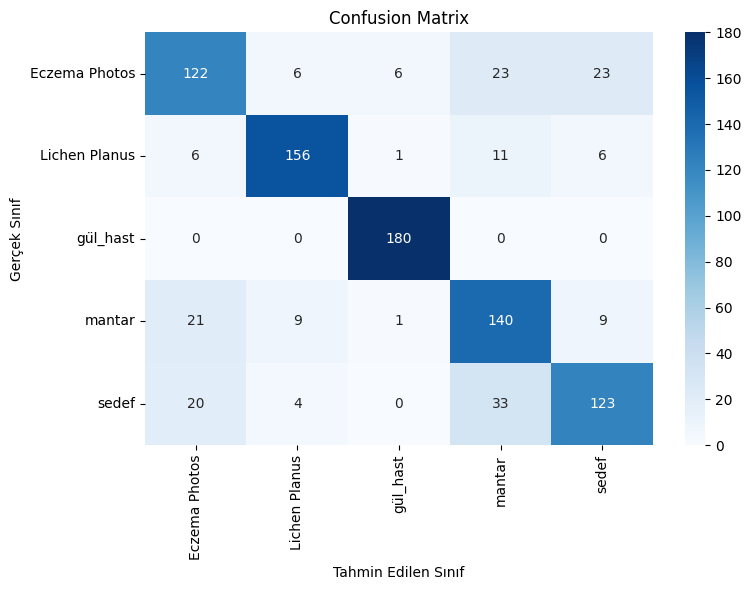

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_preds)
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.ylabel("Gerçek Sınıf")
plt.xlabel("Tahmin Edilen Sınıf")
plt.tight_layout()
plt.show()

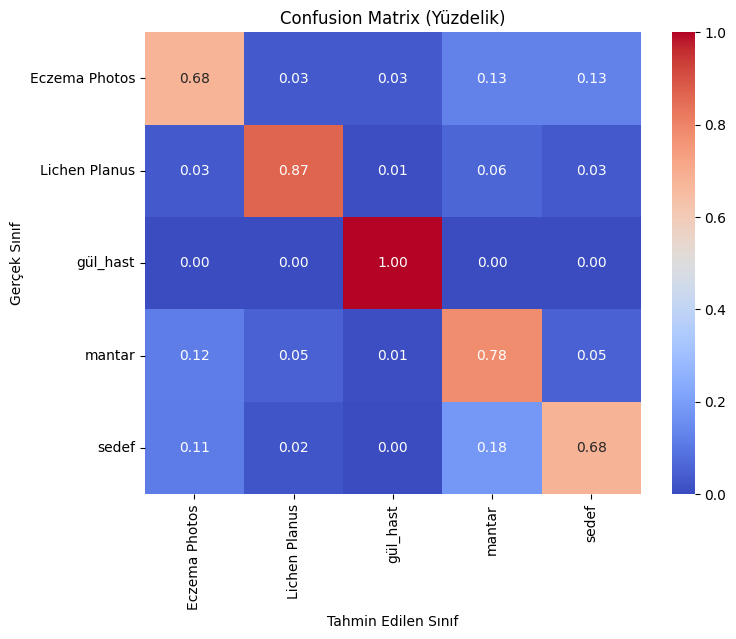

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(all_labels, all_preds)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

cm_df = pd.DataFrame(cm_percent, index=class_names, columns=class_names)

plt.figure(figsize=(8,6))
sns.heatmap(cm_df, annot=True, fmt='.2f', cmap='coolwarm', cbar=True)
plt.title("Confusion Matrix (Yüzdelik)")
plt.ylabel("Gerçek Sınıf")
plt.xlabel("Tahmin Edilen Sınıf")
plt.show()

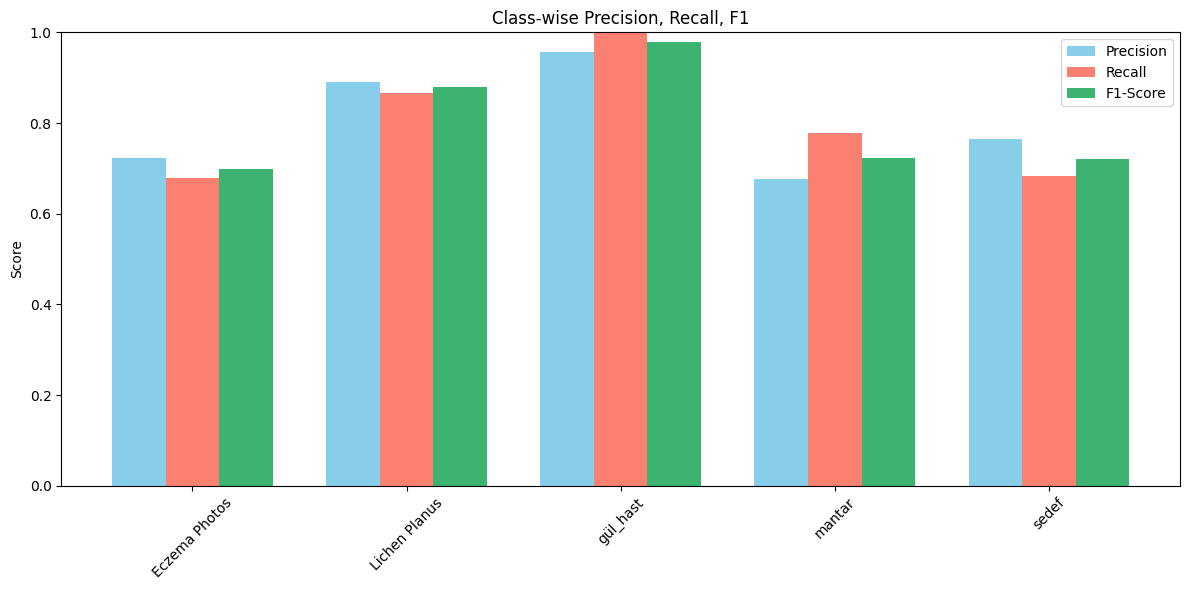

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import matplotlib.pyplot as plt

precisions = precision_score(all_labels, all_preds, average=None, zero_division=0)
recalls = recall_score(all_labels, all_preds, average=None, zero_division=0)
f1_scores = f1_score(all_labels, all_preds, average=None, zero_division=0)

x = np.arange(len(class_names))
width = 0.25

plt.figure(figsize=(12,6))
plt.bar(x - width, precisions, width, label='Precision', color='skyblue')
plt.bar(x, recalls, width, label='Recall', color='salmon')
plt.bar(x + width, f1_scores, width, label='F1-Score', color='mediumseagreen')

plt.xticks(x, class_names, rotation=45)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Class-wise Precision, Recall, F1")
plt.legend()
plt.tight_layout()
plt.show()

/tmp/ipython-input-185495237.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_names, y=class_acc, palette="viridis")


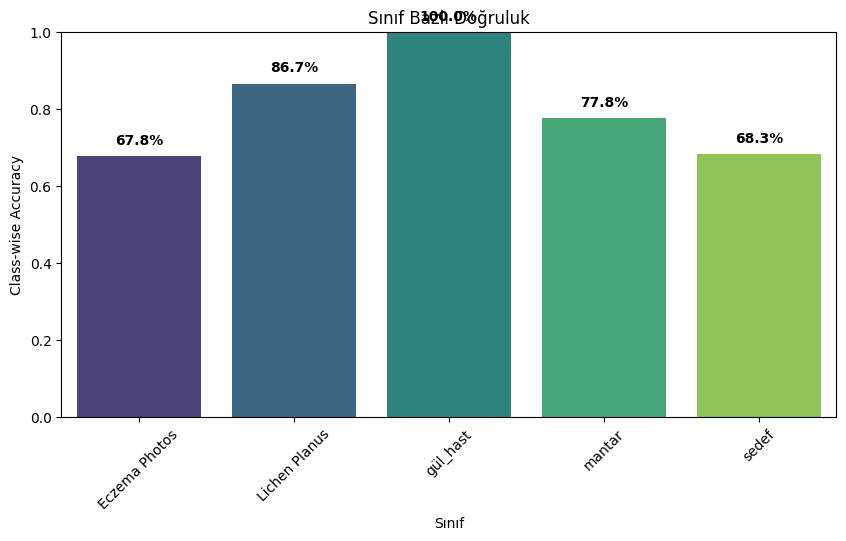

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cm = cm.astype(np.float64)
class_acc = cm.diagonal() / cm.sum(axis=1)
class_acc = np.nan_to_num(class_acc)

plt.figure(figsize=(10, 5))

sns.barplot(x=class_names, y=class_acc, palette="viridis")

plt.ylim(0, 1)
plt.ylabel("Class-wise Accuracy")
plt.xlabel("Sınıf")
plt.title("Sınıf Bazlı Doğruluk")
plt.xticks(rotation=45)

for i, v in enumerate(class_acc):
    plt.text(i, v + 0.03, f"{v*100:.1f}%", ha='center', fontsize=10, weight='bold')

plt.show()


--- Collecting Probabilities for ROC Curve ---


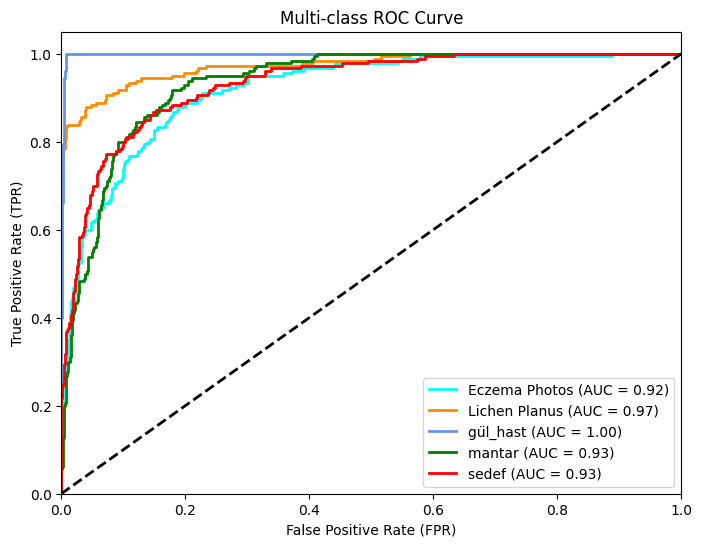

In [ ]:
import torch
import numpy as np
from tqdm import tqdm
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
from itertools import cycle

model_ft.eval()

all_labels = []
all_probs = []

print("\n--- Collecting Probabilities for ROC Curve ---")

with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc='Collecting Probabilities'):
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model_ft(inputs)
        probabilities = torch.softmax(outputs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probabilities.cpu().numpy())

all_labels = np.array(all_labels)
all_probs = np.array(all_probs)

all_labels_bin = label_binarize(all_labels, classes=range(len(class_names)))
n_classes = len(class_names)

plt.figure(figsize=(8, 6))

colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green', 'red', 'purple'])

for i, color in zip(range(n_classes), colors):

    if np.sum(all_labels_bin[:, i]) == 0:
        print(f"⚠ {class_names[i]} sınıfı için gerçek label yok → ROC çizilmedi.")
        continue

    if np.all(all_probs[:, i] == 0):
        print(f"⚠ {class_names[i]} sınıfı için tahmin yok → ROC çizilmedi.")
        continue

    fpr, tpr, _ = roc_curve(all_labels_bin[:, i], all_probs[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, lw=2, color=color,
             label=f"{class_names[i]} (AUC = {roc_auc:.2f})")

plt.plot([0, 1], [0, 1], "k--", lw=2)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("Multi-class ROC Curve")
plt.legend(loc="lower right")

plt.show()